# Coffee Chain Sales Analysis

**Questions**

1. What drove the jump in sales from May 2014?
2. Which products and states are really the most profitable once the size of each group is taken into account?
3. Where does the chain miss its profit targets?

**Data.** The [Coffee Chain Sales](https://www.kaggle.com/datasets/amruthayenikonda/coffee-chain-sales-dataset/data) dataset from Kaggle: 1,062 records from October 2012 to August 2015, with sales, costs, marketing, profit and targets per product and US state. The source does not say how the data was collected.

This is a revised version of my 2024 project. The original notebook is kept in [`archive/`](archive/original_analysis_2024.ipynb). Section 7 explains what changed and why.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

DATA = Path("../data/coffee_chain_sales.csv")
FIG = Path("../images"); FIG.mkdir(exist_ok=True)

BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#c9c8c2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
})

## 1. Load and clean

Column names are stripped of stray spaces (the original file has `Target_sales ` with a trailing space), the column `Inventory Margin` is renamed to `Inventory` to match its description, and dates are parsed.

In [2]:
df = pd.read_csv(DATA)
df.columns = df.columns.str.strip()
df = df.rename(columns={"Inventory Margin": "Inventory", "DifferenceBetweenActualandTargetProfit": "Profit_vs_target"})
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")
df["Month"] = df["Date"].dt.to_period("M")
print(f"{len(df):,} records, {df.shape[1]} columns, {df.Date.min():%b %Y} to {df.Date.max():%b %Y}")
df.head()

1,062 records, 22 columns, Oct 2012 to Aug 2015


,Area Code,Cogs,Profit_vs_target,Date,Inventory,Margin,Market_size,Market,Marketing,Product_line,...,Profit,Sales,State,Target_cogs,Target_margin,Target_profit,Target_sales,Total_expenses,Type,Month
0,303,51,-35,2012-10-01,503,71,Major Market,Central,46,Leaves,...,-5,122,Colorado,30,60,30,90,76,Decaf,2012-10
1,970,52,-24,2012-10-01,405,71,Major Market,Central,17,Leaves,...,26,123,Colorado,30,60,50,90,45,Decaf,2012-10
2,409,43,-22,2012-10-02,419,64,Major Market,South,13,Leaves,...,28,107,Texas,30,60,50,90,36,Decaf,2012-10
3,850,38,-15,2012-10-03,871,56,Major Market,East,10,Leaves,...,35,94,Florida,40,60,50,100,21,Regular,2012-10
4,562,72,6,2012-10-04,650,110,Major Market,West,23,Leaves,...,56,182,California,20,60,50,80,54,Regular,2012-10


## 2. Data quality checks

Before drawing conclusions, it is worth checking whether the numbers add up. Three accounting identities should hold in every record: sales minus cost of goods equals margin, margin minus expenses equals profit, and the profit-versus-target column equals profit minus target profit.

In [3]:
checks = pd.Series({
    "Missing values": int(df.isna().sum().sum()),
    "Duplicate rows": int(df.duplicated().sum()),
    "Records per calendar day (max)": int(df.groupby("Date").size().max()),
    "Sales - COGS = Margin": f"{((df.Sales - df.Cogs) == df.Margin).mean():.0%} of records",
    "Margin - Total expenses = Profit": f"{((df.Margin - df.Total_expenses) == df.Profit).mean():.0%} of records",
    "Profit - Target profit = Profit_vs_target": f"{((df.Profit - df.Target_profit) == df.Profit_vs_target).mean():.0%} of records",
    "Records with a loss": f"{(df.Profit < 0).mean():.0%}",
})
checks.to_frame("result")

,result
Missing values,0
Duplicate rows,0
Records per calendar day (max),2
Sales - COGS = Margin,50% of records
Margin - Total expenses = Profit,51% of records
Profit - Target profit = Profit_vs_target,100% of records
Records with a loss,13%


**Reading.** The data has no missing values or duplicates, but two things stand out:

- **There is one record per day** (one day has two). A real coffee chain with 20 states and 13 products would generate many transactions a day, so this is a sample, or a synthetic dataset built on a daily grid.
- **Two of the three accounting identities hold in only about half of the records.** In the other half, sales minus cost of goods is always higher than the reported margin, by 2 to 50. The columns may follow definitions that are not documented.

The analysis below relies on the reported `Profit` and `Sales` columns, and treats the results as illustrative rather than as facts about a real business.

## 3. What happened in May 2014?

,Before May 2014,From May 2014,Change
Sales per record,112.8,284.5,+152%
Target sales per record,91.8,260.1,+183%
Marketing per record,18.0,45.3,+152%
Marketing as share of sales,15.9%,15.9%,+0%
Profit margin,25.4%,34.7%,+37%
Records per month,30.4,30.2,-1%


New product lines, products or states after May 2014: {'Product_line': [], 'Product': [], 'State': []}


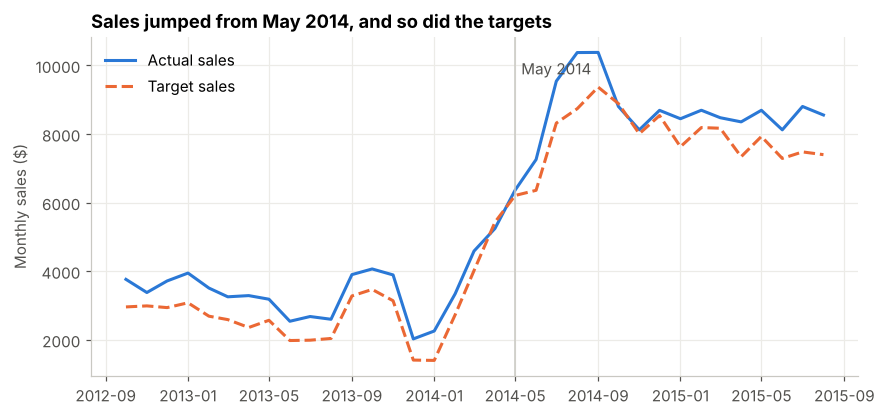

In [4]:
monthly = df.groupby("Month")[["Sales", "Target_sales", "Marketing", "Profit"]].sum()
monthly.index = monthly.index.to_timestamp()
before, after = df[df.Date < "2014-05-01"], df[df.Date >= "2014-05-01"]

summary = pd.DataFrame({
    "Before May 2014": [before.Sales.mean(), before.Target_sales.mean(), before.Marketing.mean(),
                        before.Marketing.sum() / before.Sales.sum(), before.Profit.sum() / before.Sales.sum(),
                        before.groupby("Month").size().mean()],
    "From May 2014": [after.Sales.mean(), after.Target_sales.mean(), after.Marketing.mean(),
                      after.Marketing.sum() / after.Sales.sum(), after.Profit.sum() / after.Sales.sum(),
                      after.groupby("Month").size().mean()],
}, index=["Sales per record", "Target sales per record", "Marketing per record",
          "Marketing as share of sales", "Profit margin", "Records per month"])
summary["Change"] = summary.iloc[:, 1] / summary.iloc[:, 0] - 1
display(summary.style.format("{:.1f}").format("{:.1%}", subset=pd.IndexSlice[["Marketing as share of sales", "Profit margin"], :])
        .format("{:+.0%}", subset=["Change"]))

new = {col: set(after[col]) - set(before[col]) for col in ["Product_line", "Product", "State"]}
print("New product lines, products or states after May 2014:", {k: sorted(v) for k, v in new.items()})

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly.index, monthly.Sales, color=BLUE, lw=2, label="Actual sales")
ax.plot(monthly.index, monthly.Target_sales, color=ORANGE, lw=2, ls="--", label="Target sales")
ax.axvline(pd.Timestamp("2014-05-01"), color=GREY, lw=1)
ax.text(pd.Timestamp("2014-05-10"), monthly.Sales.max() * 0.98, "May 2014", color=MUTED, va="top")
ax.set(ylabel="Monthly sales ($)", title="Sales jumped from May 2014, and so did the targets")
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIG / "01_sales_vs_target.png"); plt.show()

**Reading.** The number of records per month did not change, so the jump is real growth per record: average sales rose from about 113 to 285, a 152% increase, and the profit margin rose from 25% to 35%. No new product lines, products or states appeared, which rules out expansion as the explanation. The new finding is that **the sales targets rose by almost the same amount**, from 92 to 260 per record. The jump was planned in advance. It reflects a business decision, such as new pricing, larger stores or a change in how records are aggregated, rather than a surprise.

## 4. Does marketing drive sales?

The original analysis found a 0.97 correlation between monthly marketing spend and monthly sales, and concluded that marketing drives growth. Before accepting that, it is worth checking marketing as a share of sales.

Correlation of monthly marketing and sales: 0.97
Marketing as share of sales: 15.9% overall, 15.9% before May 2014, 15.9% after; monthly range 11.8% to 19.2%


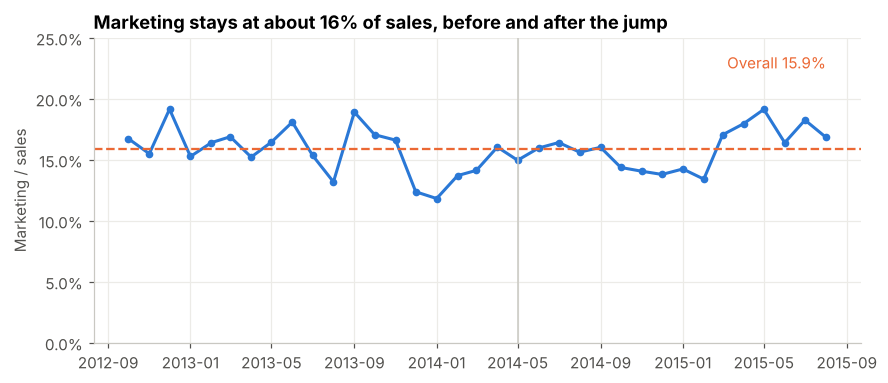

In [5]:
monthly["Marketing_share"] = monthly.Marketing / monthly.Sales
corr = monthly.Sales.corr(monthly.Marketing)
overall = df.Marketing.sum() / df.Sales.sum()
print(f"Correlation of monthly marketing and sales: {corr:.2f}")
print(f"Marketing as share of sales: {overall:.1%} overall, {before.Marketing.sum()/before.Sales.sum():.1%} before May 2014, "
      f"{after.Marketing.sum()/after.Sales.sum():.1%} after; monthly range {monthly.Marketing_share.min():.1%} to {monthly.Marketing_share.max():.1%}")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(monthly.index, monthly.Marketing_share, color=BLUE, lw=2, marker="o", markersize=4)
ax.axhline(overall, color=ORANGE, lw=1.5, ls="--")
ax.text(monthly.index[-1], 0.225, f"Overall {overall:.1%}", color=ORANGE, ha="right")
ax.axvline(pd.Timestamp("2014-05-01"), color=GREY, lw=1)
ax.set_ylim(0, 0.25); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(ylabel="Marketing / sales", title="Marketing stays at about 16% of sales, before and after the jump")
fig.savefig(FIG / "02_marketing_share_of_sales.png"); plt.show()

**Reading.** Marketing is 15.9% of sales both before and after May 2014, and every month stays between roughly 12% and 19%. When spend moves in lockstep with sales like this, the most likely explanation is that the marketing budget is set as a fixed share of sales. In that case sales drive marketing, not the other way round, and the 0.97 correlation says nothing about whether extra marketing would bring extra sales.

Answering that question would need variation that is not tied to sales: for example, a campaign run in some states and not others, or a period where the budget was changed on purpose.

## 5. Which products and states are really the most profitable?

Products and states appear in different numbers of records. California has 72 records, while Illinois has 54. Comparing total profit therefore partly compares how much data each group has. Profit margin and profit per record are fairer measures.

,records,sales,profit,margin
Product,,,,
Green Tea,72,"8,520",89,1.0%
Mint,48,"8,342","1,286",15.4%
Amaretto,48,"6,781","1,352",19.9%
Caffe Mocha,120,"21,716","4,687",21.6%
Decaf Irish Cream,96,"14,831","3,201",21.6%
Caffe Latte,54,"8,665","2,716",31.3%
Lemon,120,"24,048","7,614",31.7%
Earl Grey,72,"16,546","5,975",36.1%
Chamomile,96,"19,295","7,006",36.3%


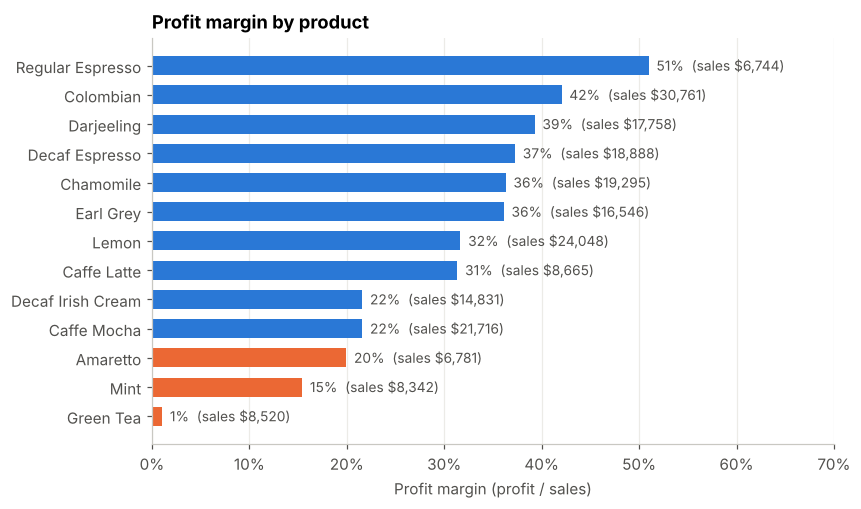

In [6]:
products = (df.groupby("Product").agg(records=("Sales", "size"), sales=("Sales", "sum"), profit=("Profit", "sum"))
            .assign(margin=lambda d: d.profit / d.sales).sort_values("margin"))
display(products.style.format({"sales": "{:,.0f}", "profit": "{:,.0f}", "margin": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 4.8))
colors = [ORANGE if m < 0.2 else BLUE for m in products.margin]
ax.barh(range(len(products)), products.margin, color=colors, height=0.65)
ax.set_yticks(range(len(products)), products.index)
for y, (m, s) in enumerate(zip(products.margin, products.sales)):
    ax.text(m + 0.008, y, f"{m:.0%}  (sales ${s:,.0f})", va="center", color=MUTED, fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xlim(0, 0.7)
ax.set(xlabel="Profit margin (profit / sales)", title="Profit margin by product")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "03_product_margin.png"); plt.show()

**Reading.** Margins range from 1% to 51%. **Green Tea** stands out: $8,520 in sales but only $89 in profit, a 1% margin. Mint and Amaretto are also below 20%. At the other end, Regular Espresso has the highest margin (51%) but appears in only 18 records, so it may be under-sold rather than a niche product. Colombian combines the highest sales with a 42% margin.

,records,sales,profit,profit_per_record,margin,rank_total_profit,rank_profit_per_record
State,,,,,,,
Illinois,54,"16,812","7,380",136.7,43.9%,1,1
New York,48,"17,731","5,565",115.9,31.4%,3,2
Massachusetts,36,"7,339","3,710",103.1,50.6%,7,3
California,72,"23,032","7,340",101.9,31.9%,2,4
Iowa,54,"13,359","5,412",100.2,40.5%,4,5
Texas,42,"9,092","3,803",90.5,41.8%,6,6
Colorado,66,"12,112","4,450",67.4,36.7%,5,7
Oklahoma,42,"7,298","2,351",56.0,32.2%,13,8
Florida,54,"8,825","2,794",51.7,31.7%,10,9


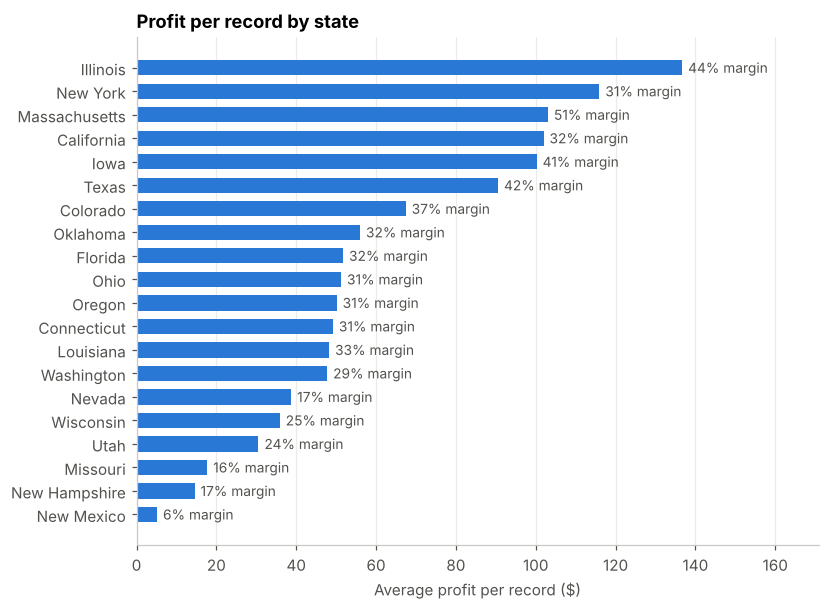

In [7]:
states = (df.groupby("State").agg(records=("Sales", "size"), sales=("Sales", "sum"), profit=("Profit", "sum"),
                                   profit_per_record=("Profit", "mean"))
          .assign(margin=lambda d: d.profit / d.sales))
states["rank_total_profit"] = states.profit.rank(ascending=False).astype(int)
states["rank_profit_per_record"] = states.profit_per_record.rank(ascending=False).astype(int)
states = states.sort_values("profit_per_record", ascending=False)
display(states.style.format({"sales": "{:,.0f}", "profit": "{:,.0f}", "profit_per_record": "{:.1f}", "margin": "{:.1%}"}))

top = states.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(range(len(top)), top.profit_per_record, color=BLUE, height=0.65)
ax.set_yticks(range(len(top)), top.index)
for y, (v, m) in enumerate(zip(top.profit_per_record, top.margin)):
    ax.text(v + 1.5, y, f"{m:.0%} margin", va="center", color=MUTED, fontsize=9)
ax.set(xlabel="Average profit per record ($)", title="Profit per record by state")
ax.grid(axis="y", visible=False); ax.set_xlim(0, top.profit_per_record.max() * 1.25)
fig.savefig(FIG / "04_state_profit_per_record.png"); plt.show()

**Reading.** By total profit, Illinois and California are almost tied for first place. Per record, Illinois is clearly ahead ($137 against $102), and its margin is 44% against California's 32%. California's total is partly the result of having more records. At the bottom, New Mexico, New Hampshire and Missouri earn $5 to $18 per record, with margins of 6% to 17%. Nevada is a different case: it has high sales but only a 17% margin, so the issue there is cost, not demand.

## 6. Where does the chain miss its profit targets?

Records that met or beat the profit target: 44%


,records,hit_rate,avg_gap
State,,,
Missouri,54,19%,-13.0
New Mexico,42,19%,-13.0
New Hampshire,42,21%,-10.2
Utah,72,33%,-10.3
Ohio,54,37%,-7.7
Oregon,66,39%,-1.7
Wisconsin,54,41%,-8.6
Colorado,66,42%,-2.3
Louisiana,42,43%,+0.1


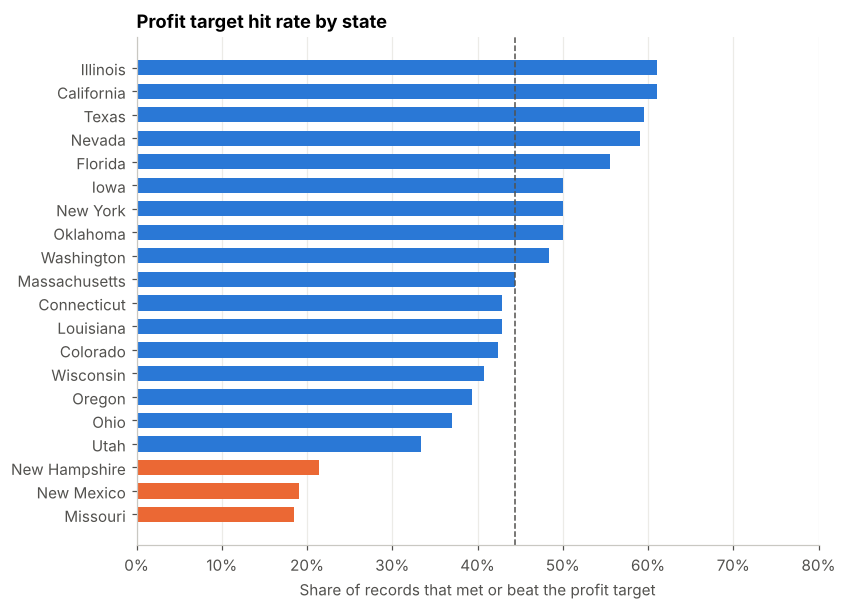

In [8]:
targets = (df.groupby("State").agg(records=("Profit", "size"),
                                   hit_rate=("Profit_vs_target", lambda s: (s >= 0).mean()),
                                   avg_gap=("Profit_vs_target", "mean"))
           .sort_values("hit_rate"))
print(f"Records that met or beat the profit target: {(df.Profit_vs_target >= 0).mean():.0%}")
display(targets.style.format({"hit_rate": "{:.0%}", "avg_gap": "{:+.1f}"}))

fig, ax = plt.subplots(figsize=(8, 6))
colors = [ORANGE if h < 0.3 else BLUE for h in targets.hit_rate]
ax.barh(range(len(targets)), targets.hit_rate, color=colors, height=0.65)
ax.set_yticks(range(len(targets)), targets.index)
ax.axvline((df.Profit_vs_target >= 0).mean(), color=MUTED, lw=1, ls="--")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xlim(0, 0.8)
ax.set(xlabel="Share of records that met or beat the profit target", title="Profit target hit rate by state")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "05_target_hit_rate.png"); plt.show()

**Reading.** Overall, only 44% of records meet or beat the profit target. Missouri, New Mexico and New Hampshire meet it in only about one record in five, and miss it by $10 to $13 on average. These are the same three states with the lowest profit per record in section 5, so they combine weak results with targets that may be unrealistic. Iowa and New York have the largest positive average gaps (about +$20), which may mean their targets are set too low.

## 7. What changed from the first version

| Topic | First version (2024) | This version |
|---|---|---|
| Data quality | Missing values only | Accounting identities checked; data treated as a sample with undocumented definitions |
| Sales jump | Searched for causes in products, states and marketing | Adds that sales targets rose by the same amount, so the jump was planned |
| Marketing | 0.97 correlation read as "marketing drives sales" | Marketing is a fixed ~16% of sales, so the correlation reflects how the budget is set, not its effect |
| Products and states | Ranked by total sales and profit | Ranked by margin and profit per record, which corrects for different numbers of records |
| Targets | Average gaps by state | Hit rate by state, linked to profitability |
| Charts | Dual-axis chart for sales and marketing | One axis per measure |

## 8. Summary

| # | Finding | Number | Recommendation |
|---|---|---|---|
| 1 | The May 2014 jump was planned | Sales per record +152%; target sales per record +183% | Find out what changed in May 2014 (pricing, store size, data aggregation) before attributing growth to any one factor |
| 2 | Marketing follows sales | 15.9% of sales before and after the jump | Test marketing with controlled variation, for example a campaign in some states only |
| 3 | Green Tea earns almost nothing | 1% margin on $8,520 in sales | Review its price and cost, or reduce its promotion |
| 4 | Illinois is the most profitable state per record | $137 per record, 44% margin | Use Illinois as the benchmark for cost structure |
| 5 | Three states combine low profit and missed targets | Missouri, New Mexico, New Hampshire: 6% to 17% margin, about 20% target hit rate | Review both their operations and how their targets are set |

**Limitation.** The dataset has about one record per day and half the records fail basic accounting identities, so these findings show the method rather than describing a real chain.